# LimeoX AI/ML Foundation Program
## Feature Engineering for Scraped News Data

This notebook is the complete practical feature engineering lesson. Run the cells from top to bottom.

The objective is to take your scraped news dataset — containing fields such as `title`, `text`, `url`, `domain`, `author`, `published_at`, and `scraped_at` — and transform it into structured numerical and categorical features suitable for machine learning.

> **Dataset:** set `DATA_PATH` in Section 2 to your scraped CSV. If the file is not found, the notebook creates a small synthetic news dataset so every cell can still run for practice.

## 1. What is feature engineering?

Feature engineering is the process of transforming raw data into meaningful variables (features) that help machine learning models identify patterns.

For example, a scraped article might contain:

| Raw field | Example |
|---|---|
| Title | Tesla Shares Surge 8% After Strong Earnings |
| Domain | reuters.com |
| Published date | 2026-10-29 09:30:00 |
| Article text | Tesla shares rose sharply after the company reported... |
| URL | reuters.com/markets/companies/tesla... |

We can extract additional features:

| Engineered feature | Value |
|---|---|
| `title_word_count` | 8 |
| `title_char_count` | 48 |
| `title_contains_number` | 1 |
| `body_word_count` | 450 |
| `url_path_depth` | 2 |
| `published_hour` | 9 |
| `published_dayofweek` | 3 |
| `domain` | reuters.com |
| `title_tfidf_features` | Sparse numerical vector |

There are several major categories of feature engineering:

1. Numerical feature engineering
2. Text feature engineering
3. URL and domain feature engineering
4. Date/time feature engineering
5. Categorical feature engineering
6. Statistical feature engineering
7. NLP-based feature engineering
8. Feature selection and dimensionality reduction

## 2. Load the dataset and inspect its structure

First, load the dataset and inspect its columns.

In [68]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.parse import urlparse
DATA_PATH = r"..\Task 5 (Categorization)\news_categorized.csv" # Change this to your dataset path

The helper below builds a small synthetic news dataset. It is used **only** when `DATA_PATH` does not exist, so students can practise before their own scraped data is ready.

In [69]:
def make_sample_news_data(n=240, seed=42):
    """Create a small synthetic scraped-news dataset for practice."""
    rng = np.random.default_rng(seed)
    companies = ["Tesla", "Apple", "Nvidia", "Amazon", "Pfizer", "Moderna", "Microsoft", "Meta"]
    topics = {
        "Finance": {
            "domains": ["reuters.com", "bloomberg.com", "ft.com"],
            "section": "markets/companies",
            "titles": [
                "{c} Shares Surge {p}% After Strong Earnings",
                "{c} Revenue Beats Forecast as Investors Cheer",
                "Stock Market Falls {p}% as Inflation Fears Return",
                "{c} Announces Dividend Increase and Share Buyback",
            ],
            "sentences": [
                "{c} shares rose {p}% after the company reported quarterly earnings above expectations.",
                "Investors focused on revenue growth, profit margins and the interest rate outlook.",
                "The stock market reacted to new inflation data released on Tuesday.",
                "Analysts raised their forecast and price targets following the results.",
                "The company also announced a dividend and an expanded share buyback.",
            ],
        },
        "Technology": {
            "domains": ["techcrunch.com", "theverge.com", "wired.com"],
            "section": "tech/ai",
            "titles": [
                "{c} Unveils New AI Chip for Data Centers",
                "Is {c}'s New Software Update Worth Installing?",
                "{c} Launches Developer Tools for Generative AI",
                "Startup Raises ${p}0M to Build Open-Source Models",
            ],
            "sentences": [
                "{c} introduced a new chip designed to speed up artificial intelligence workloads.",
                "Developers can access the tools through a public API starting next month.",
                "The update brings performance improvements and new privacy controls.",
                "Engineers said the model was trained on a large cluster of GPUs.",
                "Read more at https://example.com/tech for the full specifications.",
            ],
        },
        "Healthcare": {
            "domains": ["statnews.com", "medicalnewstoday.com", "healthline.com"],
            "section": "health/research",
            "titles": [
                "{c} Vaccine Trial Shows {p}0% Efficacy",
                "New Study Links Sleep to Heart Health",
                "FDA Approves {c} Treatment for Rare Disease",
                "Hospitals Report Rise in Flu Cases This Winter",
            ],
            "sentences": [
                "Researchers enrolled thousands of patients in the clinical trial.",
                "The FDA said the treatment met its primary safety and efficacy endpoints.",
                "Doctors recommend regular check-ups and adequate sleep.",
                "The study was published in a peer-reviewed medical journal.",
                "Public health officials urged people to get vaccinated before winter.",
            ],
        },
        "Politics": {
            "domains": ["cnn.com", "bbc.com", "politico.com"],
            "section": "politics/news",
            "titles": [
                "Senate Passes Budget Bill After Long Debate",
                "What Does the New Trade Policy Mean for Voters?",
                "Lawmakers Question {c} CEO Over Data Privacy",
                "Election Polls Tighten With {p} Weeks to Go",
            ],
            "sentences": [
                "Lawmakers debated the proposal for several hours before the vote.",
                "The government said the policy would take effect next year.",
                "Opposition leaders criticised the plan and called for amendments.",
                "Voters in several states expressed concern about the economy.",
                "The committee will hold another hearing next week.",
            ],
        },
    }
    authors = ["Jane Smith", "Ali Khan", "Maria Garcia", "Chen Wei", "Sara Ahmed", None]
    start = pd.Timestamp("2026-09-01")
    rows = []
    for i in range(n):
        category = list(topics)[i % len(topics)]
        topic = topics[category]
        c = str(rng.choice(companies))
        p = int(rng.integers(1, 15))
        title = str(rng.choice(topic["titles"])).format(c=c, p=p)
        paragraphs = []
        for _ in range(int(rng.integers(2, 5))):
            picked = rng.choice(topic["sentences"], size=int(rng.integers(2, 4)), replace=False)
            paragraphs.append(" ".join(str(s).format(c=c, p=p) for s in picked))
        domain = str(rng.choice(topic["domains"]))
        slug = re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-")
        published = start + pd.Timedelta(hours=int(rng.integers(0, 24 * 60)))
        scraped = published + pd.Timedelta(minutes=int(rng.integers(10, 72 * 60)))
        rows.append({
            "title": title,
            "text": "\n\n".join(paragraphs),
            "url": f"https://www.{domain}/{topic['section']}/{slug}-{i}/",
            "domain": domain,
            "author": authors[int(rng.integers(len(authors)))],
            "published_at": published.strftime("%Y-%m-%d %H:%M:%S"),
            "scraped_at": scraped.strftime("%Y-%m-%d %H:%M:%S"),
            "category": category,
        })
    return pd.DataFrame(rows)

In [70]:
if Path(DATA_PATH).exists():
    df = pd.read_csv(DATA_PATH)
else:
    print(f"'{DATA_PATH}' not found, so a synthetic sample dataset is used for practice.")
    df = make_sample_news_data()

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())

Dataset Shape: (99900, 16)

Columns:
['source_row_index', 'title_clean', 'author_clean', 'published_at_utc', 'year', 'time', 'news_url_clean', 'source', 'content_clean', 'domain', 'published_at_utc_parsed', 'duplicate_signature_candidate', 'validation_issue_count', 'validation_issue_codes', 'validation_disposition', 'category']


,source_row_index,title_clean,author_clean,published_at_utc,year,time,news_url_clean,source,content_clean,domain,published_at_utc_parsed,duplicate_signature_candidate,validation_issue_count,validation_issue_codes,validation_disposition,category
0,0,This free app adds one of my favorite iPhone f...,Yash Wate,2026-10-26,2026.0,10:30:56,https://www.androidauthority.com/this-free-app...,Android Authority,Affiliate links on Android Authority may earn ...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT,Technology
1,1,Samsung slices into Apple’s iPhone Duo trouble...,Hillary Keverenge,2026-10-26,2026.0,10:44:33,https://www.androidauthority.com/samsung-mocks...,Android Authority,Affiliate links on Android Authority may earn ...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT,Technology
2,2,Polled readers say this core Google feature ma...,Andy Walker,2026-10-26,2026.0,09:53:34,https://www.androidauthority.com/matters-most-...,Android Authority,Affiliate links on Android Authority may earn ...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT,Technology
3,3,Chrome without Google: These are the 9 best Ch...,Andy Walker,2026-10-26,2026.0,09:30:56,https://www.androidauthority.com/google-chrome...,Android Authority,Affiliate links on Android Authority may earn ...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT,Technology
4,4,7 features I want next from Google Wallet afte...,Andrew Grush,2026-10-26,2026.0,09:00:07,https://www.androidauthority.com/google-wallet...,Android Authority,Affiliate links on Android Authority may earn ...,www.androidauthority.com,2026-10-26 00:00:00+00:00,False,0,NaN,ACCEPT,Technology


For this lesson, we will standardize these column names. Change the right-hand values according to your actual CSV.

In [71]:
COLUMN_MAP = {
    "title": "title_clean",
    "text": "content_clean",
    "url": "news_url_clean",
    "domain": "domain",
    "author": "author_clean",
    "published_at": "published_at_utc",
    "scraped_at": None,
    "category": "category",
}

In [72]:
def resolve_column(df, name):
    if name is None:
        return None
    if name in df.columns:
        return name
    lookup = {
        str(col).strip().lower(): col
        for col in df.columns
    }
    return lookup.get(str(name).strip().lower())


for standard_name, actual_name in COLUMN_MAP.items():
    actual_column = resolve_column(df, actual_name)
    if actual_column is not None:
        df[standard_name] = df[actual_column]

for col in COLUMN_MAP:
    if col not in df.columns:
        df[col] = pd.NA

print(df.columns.tolist())

['source_row_index', 'title_clean', 'author_clean', 'published_at_utc', 'year', 'time', 'news_url_clean', 'source', 'content_clean', 'domain', 'published_at_utc_parsed', 'duplicate_signature_candidate', 'validation_issue_count', 'validation_issue_codes', 'validation_disposition', 'category', 'title', 'text', 'url', 'author', 'published_at', 'scraped_at']


## 3. Text normalization and preprocessing

Before generating text features, normalize the text.

Typical operations include:

- Removing unnecessary whitespace.
- Handling missing values.
- Standardizing text representation.
- Removing unwanted HTML artifacts if present.

We should preserve the original text because numbers, punctuation, financial symbols, and tickers can carry useful information.

In [73]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    # Remove null characters
    text = text.replace("\x00", " ")
    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)
    return text.strip()


df["title_clean"] = df["title"].apply(clean_text)
df["text_clean"] = df["text"].apply(clean_text)

# Lowercase versions for text processing
df["title_lower"] = df["title_clean"].str.lower()
df["text_lower"] = df["text_clean"].str.lower()

display(df[["title_clean", "text_clean"]].head())

,title_clean,text_clean
0,This free app adds one of my favorite iPhone f...,Affiliate links on Android Authority may earn ...
1,Samsung slices into Apple’s iPhone Duo trouble...,Affiliate links on Android Authority may earn ...
2,Polled readers say this core Google feature ma...,Affiliate links on Android Authority may earn ...
3,Chrome without Google: These are the 9 best Ch...,Affiliate links on Android Authority may earn ...
4,7 features I want next from Google Wallet afte...,Affiliate links on Android Authority may earn ...


> **Important:** Do not automatically remove stopwords, numbers, or punctuation from every text column. Whether they are useful depends on the prediction task.

# Part A — Numerical Feature Engineering

## 4. Title-based features

A news headline contains useful structural information. We can extract:

- Character count
- Word count
- Sentence count
- Number of digits
- Uppercase character count
- Exclamation marks
- Question marks
- Average word length
- Unique word ratio

### 4.1 Character count

Measures the total number of characters in the title.

In [74]:
df["title_char_count"] = (
    df["title_clean"].str.len()
)

### 4.2 Word count

Measures the number of words in the title.

In [75]:
def word_count(text):
    words = re.findall(r"\b\w+\b", text)
    return len(words)


df["title_word_count"] = (
    df["title_clean"].apply(word_count)
)

### 4.3 Average word length

Measures the average length of words in a title.

In [76]:
def average_word_length(text):
    words = re.findall(r"\b\w+\b", text)
    if len(words) == 0:
        return 0
    return np.mean([
        len(word) for word in words
    ])


df["title_avg_word_length"] = (
    df["title_clean"].apply(average_word_length)
)

### 4.4 Number of digits

Useful for detecting headlines containing stock prices, percentages, years, and numerical claims.

In [77]:
df["title_digit_count"] = (
    df["title_clean"].apply(
        lambda x: sum(char.isdigit() for char in x)
    )
)

### 4.5 Uppercase ratio

Measures the proportion of uppercase characters.

In [78]:
def uppercase_ratio(text):
    if len(text) == 0:
        return 0
    uppercase = sum(
        char.isupper() for char in text
    )
    return uppercase / len(text)


df["title_uppercase_ratio"] = (
    df["title_clean"].apply(uppercase_ratio)
)

### 4.6 Punctuation features

In [79]:
df["title_exclamation_count"] = (
    df["title_clean"].str.count("!")
)
df["title_question_count"] = (
    df["title_clean"].str.count(r"\?")
)
df["title_comma_count"] = (
    df["title_clean"].str.count(",")
)
df["title_colon_count"] = (
    df["title_clean"].str.count(":")
)
df["title_parentheses_count"] = (
    df["title_clean"].str.count(r"[()]")
)

### 4.7 Unique word ratio

Measures vocabulary diversity.

$$\text{Unique Word Ratio} = \frac{\text{Number of Unique Words}}{\text{Total Number of Words}}$$

In [80]:
def unique_word_ratio(text):
    words = re.findall(
        r"\b\w+\b",
        text.lower()
    )
    if len(words) == 0:
        return 0
    return len(set(words)) / len(words)


df["title_unique_word_ratio"] = (
    df["title_clean"].apply(unique_word_ratio)
)

### 4.8 Complete title feature extraction

Instead of creating each feature separately, we can write one reusable function.

In [81]:
def extract_text_features(text):
    if pd.isna(text):
        text = ""
    text = str(text)
    words = re.findall(
        r"\b\w+\b",
        text
    )
    word_lengths = [
        len(word) for word in words
    ]
    uppercase_count = sum(
        char.isupper() for char in text
    )
    return {
        "char_count": len(text),
        "word_count": len(words),
        "avg_word_length": (
            np.mean(word_lengths)
            if word_lengths else 0
        ),
        "digit_count": sum(
            char.isdigit() for char in text
        ),
        "uppercase_count": uppercase_count,
        "uppercase_ratio": (
            uppercase_count / len(text)
            if len(text) > 0 else 0
        ),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "comma_count": text.count(","),
        "colon_count": text.count(":"),
        "unique_word_ratio": (
            len(set(w.lower() for w in words)) / len(words)
            if words else 0
        ),
    }


title_features_df = pd.DataFrame(
    df["title_clean"].apply(extract_text_features).tolist(),
    index=df.index
).add_prefix("title_")

# Assigning (rather than concatenating) updates the columns created above
# instead of adding duplicate column names.
df[title_features_df.columns] = title_features_df

display(title_features_df.head())

,title_char_count,title_word_count,title_avg_word_length,title_digit_count,title_uppercase_count,title_uppercase_ratio,title_exclamation_count,title_question_count,title_comma_count,title_colon_count,title_unique_word_ratio
0,72,14,4.214286,0,3,0.041667,0,0,0,0,0.928571
1,68,13,4.307692,0,4,0.058824,0,0,0,0,1.000000
2,81,13,5.307692,0,3,0.037037,0,0,0,0,1.000000
3,61,10,5.100000,1,4,0.065574,0,0,0,1,1.000000
4,74,13,4.769231,1,4,0.054054,0,0,0,0,1.000000


# Part B — Article Body Feature Engineering

## 5. Extract features from article content

The article body usually contains more information than the title. We can extract structural, statistical, and linguistic features.

Useful features include:

- Total article length
- Word count
- Sentence count
- Paragraph count
- Average sentence length
- Average word length
- Unique word ratio
- Number of numerical values
- Number of URLs
- Number of uppercase words
- Financial keyword count

### 5.1 Basic article statistics

In [82]:
def extract_article_statistics(text):
    if pd.isna(text):
        text = ""
    text = str(text)
    words = re.findall(
        r"\b\w+\b",
        text
    )
    sentences = [
        s for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]
    paragraphs = [
        p for p in re.split(r"\n\s*\n", text)
        if p.strip()
    ]
    return {
        "char_count": len(text),
        "word_count": len(words),
        "sentence_count": len(sentences),
        "paragraph_count": len(paragraphs),
        "avg_word_length": (
            np.mean([len(w) for w in words])
            if words else 0
        ),
        "avg_sentence_length": (
            len(words) / len(sentences)
            if sentences else 0
        ),
        "unique_word_ratio": (
            len(set(w.lower() for w in words)) / len(words)
            if words else 0
        ),
        "number_count": len(
            re.findall(r"\b\d+(?:[.,]\d+)*%?", text)
        ),
        "url_count": len(
            re.findall(r"https?://\S+|www\.\S+", text)
        ),
        "uppercase_word_count": sum(
            1 for w in words
            if w.isupper() and len(w) > 1
        ),
    }

Apply the function.

> We apply it to the raw `text` column because `text_clean` collapses line breaks, which would make every article look like a single paragraph.

In [83]:
body_features = df["text"].apply(
    extract_article_statistics
)

body_features_df = pd.DataFrame(
    body_features.tolist(),
    index=df.index
)
body_features_df.columns = [
    "body_" + col
    for col in body_features_df.columns
]

df = pd.concat(
    [df, body_features_df],
    axis=1
)

display(
    df[[
        "body_char_count",
        "body_word_count",
        "body_sentence_count",
        "body_paragraph_count",
        "body_avg_sentence_length"
    ]].head()
)

,body_char_count,body_word_count,body_sentence_count,body_paragraph_count,body_avg_sentence_length
0,8308,1576,88,1,17.909091
1,2410,396,28,1,14.142857
2,2405,422,28,1,15.071429
3,8824,1482,77,1,19.246753
4,5705,1056,51,1,20.705882


### 5.2 Financial keyword features

For financial news, certain terms can be useful indicators of the article's subject. For example: earnings, revenue, profit, loss, stock, shares, market, forecast, acquisition, bankruptcy, dividend, inflation.

We can calculate how frequently these words appear.

In [84]:
financial_keywords = [
    "earnings",
    "revenue",
    "profit",
    "loss",
    "stock",
    "stocks",
    "shares",
    "market",
    "forecast",
    "acquisition",
    "merger",
    "bankruptcy",
    "dividend",
    "inflation",
    "interest rate",
    "investment",
    "investor",
    "debt",
    "valuation",
    "ipo"
]


def count_keywords(text, keywords):
    text = str(text).lower()
    return sum(
        len(re.findall(
            r"\b" + re.escape(keyword) + r"\b",
            text
        ))
        for keyword in keywords
    )


df["financial_keyword_count"] = df["text_clean"].apply(
    lambda text: count_keywords(text, financial_keywords)
)

display(df[["title_clean", "financial_keyword_count"]].head())

,title_clean,financial_keyword_count
0,This free app adds one of my favorite iPhone f...,0
1,Samsung slices into Apple’s iPhone Duo trouble...,0
2,Polled readers say this core Google feature ma...,0
3,Chrome without Google: These are the 9 best Ch...,1
4,7 features I want next from Google Wallet afte...,0


You can also create individual keyword indicators:

In [85]:
for keyword in financial_keywords:
    feature_name = (
        "keyword_" + keyword.replace(" ", "_")
    )
    df[feature_name] = (
        df["text_clean"]
        .str.lower()
        .str.contains(
            r"\b" + re.escape(keyword) + r"\b",
            regex=True,
            na=False
        )
        .astype(int)
    )

keyword_columns = [col for col in df.columns if col.startswith("keyword_")]
display(df[keyword_columns].head())

,keyword_earnings,keyword_revenue,keyword_profit,keyword_loss,keyword_stock,keyword_stocks,keyword_shares,keyword_market,keyword_forecast,keyword_acquisition,keyword_merger,keyword_bankruptcy,keyword_dividend,keyword_inflation,keyword_interest_rate,keyword_investment,keyword_investor,keyword_debt,keyword_valuation,keyword_ipo
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**Why is this useful?**

Suppose you want to predict whether an article belongs to the financial, technology, healthcare, or political category. Keyword features can provide an interpretable baseline.

For more advanced NLP tasks, TF-IDF and embeddings can capture contextual information beyond manually selected keywords.

# Part C — URL and Domain Feature Engineering

## 6. Extract features from article URLs

A URL contains information about the publisher, article path, and sometimes the article topic.

Example: `https://www.reuters.com/markets/companies/tesla-earnings-2026/`

Possible features:

| Feature | Example |
|---|---|
| Domain | reuters.com |
| URL length | 68 |
| Path depth | 3 |
| HTTPS | 1 |
| Query parameters | 0 |
| URL slug | tesla-earnings-2026 |

### 6.1 Extract domain

In [86]:
def extract_domain(url):
    if pd.isna(url):
        return "unknown"
    url = str(url).strip()
    if not url:
        return "unknown"
    if "://" not in url:
        url = "https://" + url
    domain = urlparse(url).netloc.lower()
    if domain.startswith("www."):
        domain = domain[4:]
    return domain if domain else "unknown"


df["domain_feature"] = df["url"].apply(
    extract_domain
)

### 6.2 URL length

In [87]:
df["url_length"] = (
    df["url"].fillna("").astype(str).str.len()
)

### 6.3 URL path depth

Path depth is the number of directory levels in a URL.

In [88]:
def url_path_depth(url):
    if pd.isna(url):
        return 0
    url = str(url).strip()
    if not url:
        return 0
    if "://" not in url:
        url = "https://" + url
    path = urlparse(url).path
    parts = [
        part for part in path.split("/")
        if part
    ]
    return len(parts)


df["url_path_depth"] = (
    df["url"].apply(url_path_depth)
)

### 6.4 Extract URL slug

In [89]:
def extract_url_slug(url):
    if pd.isna(url):
        return ""
    url = str(url).strip()
    if not url:
        return ""
    if "://" not in url:
        url = "https://" + url
    path = urlparse(url).path
    parts = [
        p for p in path.split("/")
        if p
    ]
    if not parts:
        return ""
    return parts[-1]


df["url_slug"] = df["url"].apply(
    extract_url_slug
)

display(
    df[["url", "domain_feature", "url_slug"]].head()
)

,url,domain_feature,url_slug
0,https://www.androidauthority.com/this-free-app...,androidauthority.com,this-free-app-adds-one-of-my-favorite-iphone-f...
1,https://www.androidauthority.com/samsung-mocks...,androidauthority.com,samsung-mocks-iphone-duo-foldable-ad-3727862
2,https://www.androidauthority.com/matters-most-...,androidauthority.com,matters-most-android-tablet-poll-results-3727849
3,https://www.androidauthority.com/google-chrome...,androidauthority.com,google-chrome-alternatives-android-based-on-ch...
4,https://www.androidauthority.com/google-wallet...,androidauthority.com,google-wallet-wanted-features-3724594


### 6.5 Other URL features

In [90]:
def extract_url_metadata(url):
    if pd.isna(url):
        url = ""
    url = str(url).strip()
    if not url:
        return pd.Series({
            "url_https": 0,
            "url_has_query": 0,
            "url_has_fragment": 0,
            "url_slug_length": 0
        })
    parsed = urlparse(
        url if "://" in url
        else "https://" + url
    )
    # Ignore empty parts so URLs ending with "/" still return the slug
    path_parts = [
        p for p in parsed.path.split("/")
        if p
    ]
    return pd.Series({
        "url_https": int(
            parsed.scheme.lower() == "https"
        ),
        "url_has_query": int(
            bool(parsed.query)
        ),
        "url_has_fragment": int(
            bool(parsed.fragment)
        ),
        "url_slug_length": (
            len(path_parts[-1]) if path_parts else 0
        )
    })


url_metadata = df["url"].apply(extract_url_metadata)

df = pd.concat(
    [df, url_metadata],
    axis=1
)

display(
    df[[
        "url",
        "url_https",
        "url_has_query",
        "url_has_fragment",
        "url_slug_length"
    ]].head()
)

,url,url_https,url_has_query,url_has_fragment,url_slug_length
0,https://www.androidauthority.com/this-free-app...,1,0,0,80
1,https://www.androidauthority.com/samsung-mocks...,1,0,0,44
2,https://www.androidauthority.com/matters-most-...,1,0,0,48
3,https://www.androidauthority.com/google-chrome...,1,0,0,60
4,https://www.androidauthority.com/google-wallet...,1,0,0,37


> **Important:** Domain features can cause models to memorize publishers instead of learning general patterns. If your test set contains the same publishers as your training set, performance may look better than it will on new publishers. Consider domain-based validation.

# Part D — Date and Time Feature Engineering

## 7. Extract temporal features

News articles have important temporal characteristics. For example:

- Publication hour
- Publication day
- Publication month
- Day of the week
- Weekend indicator
- Article age when scraped
- Time difference between publication and scraping

These features are especially useful for news recommendation, freshness prediction, and time-sensitive classification.

### 7.1 Convert dates to datetime

In [91]:
df["published_at"] = pd.to_datetime(
    df["published_at"],
    errors="coerce",
    utc=True
)

df["scraped_at"] = pd.to_datetime(
    df["scraped_at"],
    errors="coerce",
    utc=True
)

### 7.2 Extract year, month, day, and hour

In [92]:
df["published_year"] = (
    df["published_at"].dt.year
)
df["published_month"] = (
    df["published_at"].dt.month
)
df["published_day"] = (
    df["published_at"].dt.day
)
df["published_hour"] = (
    df["published_at"].dt.hour
)
df["published_dayofweek"] = (
    df["published_at"].dt.dayofweek
)

Day of week:

| Number | Day |
|---|---|
| 0 | Monday |
| 1 | Tuesday |
| 2 | Wednesday |
| 3 | Thursday |
| 4 | Friday |
| 5 | Saturday |
| 6 | Sunday |

### 7.3 Weekend indicator

In [93]:
df["published_is_weekend"] = (
    df["published_dayofweek"]
    .isin([5, 6])
    .astype(int)
)

### 7.4 Article age at scraping

This measures how old an article was when your scraper collected it.

$$\text{Article Age} = \text{Scraped Time} - \text{Published Time}$$

In [94]:
df["article_age_hours"] = (
    df["scraped_at"] - df["published_at"]
).dt.total_seconds() / 3600

df["article_age_days"] = (
    df["article_age_hours"] / 24
)

display(df[["published_at", "scraped_at", "article_age_hours", "article_age_days"]].head())

,published_at,scraped_at,article_age_hours,article_age_days
0,2026-10-26 00:00:00+00:00,NaT,NaN,NaN
1,2026-10-26 00:00:00+00:00,NaT,NaN,NaN
2,2026-10-26 00:00:00+00:00,NaT,NaN,NaN
3,2026-10-26 00:00:00+00:00,NaT,NaN,NaN
4,2026-10-26 00:00:00+00:00,NaT,NaN,NaN


### 7.5 Cyclical time encoding

There is an important problem with ordinary numerical encoding. For example:

- 23:00 and 00:00 are only one hour apart.
- But a machine learning model sees the numerical difference as 23.

Cyclical encoding solves this problem by representing time using sine and cosine.

$$\text{Hour}_{\sin} = \sin\left(\frac{2\pi \times \text{Hour}}{24}\right) \qquad \text{Hour}_{\cos} = \cos\left(\frac{2\pi \times \text{Hour}}{24}\right)$$

In [95]:
df["published_hour_sin"] = np.sin(
    2 * np.pi * df["published_hour"] / 24
)
df["published_hour_cos"] = np.cos(
    2 * np.pi * df["published_hour"] / 24
)

df["published_day_sin"] = np.sin(
    2 * np.pi * df["published_dayofweek"] / 7
)
df["published_day_cos"] = np.cos(
    2 * np.pi * df["published_dayofweek"] / 7
)

> **Practical application:** If you are predicting article engagement or Google Discover clicks, publication time and article freshness may be useful. However, only use information available when the prediction is made.

# Part E — Categorical Feature Engineering

## 8. Convert categorical variables into numerical representations

Machine learning algorithms generally require numerical inputs. Suppose your dataset contains:

| Domain | Category |
|---|---|
| reuters.com | Finance |
| cnn.com | Politics |
| bbc.com | World |
| techcrunch.com | Technology |

We need to encode these categories.

### 8.1 Label encoding

Each category receives an integer.

In [96]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["category_encoded"] = le.fit_transform(
    df["category"].fillna("Unknown").astype(str)
)

print(dict(zip(
    le.classes_,
    le.transform(le.classes_)
)))

{'Energy': np.int64(0), 'Health': np.int64(1), 'Market/Stocks': np.int64(2), 'Other': np.int64(3), 'Politics': np.int64(4), 'Technology': np.int64(5)}


> **Limitation:** Label encoding can create an artificial ordering. For nominal categories, such as publisher names, that ordering usually has no meaning.

### 8.2 One-hot encoding

One-hot encoding creates separate binary columns.

In [97]:
df_encoded = pd.get_dummies(
    df,
    columns=["category"],
    prefix="category",
    dummy_na=True
)

display(df_encoded.filter(like="category_").head())

,category_encoded,category_Energy,category_Health,category_Market/Stocks,category_Other,category_Politics,category_Technology,category_nan
0,5,False,False,False,False,False,True,False
1,5,False,False,False,False,False,True,False
2,5,False,False,False,False,False,True,False
3,5,False,False,False,False,False,True,False
4,5,False,False,False,False,False,True,False


Example:

| Category | Finance | Politics | Technology |
|---|---|---|---|
| Finance | 1 | 0 | 0 |
| Politics | 0 | 1 | 0 |
| Technology | 0 | 0 | 1 |

**When to use:**

- Low-cardinality categorical features.
- Article category.
- Article type.
- Language.

For high-cardinality fields such as thousands of authors or domains, one-hot encoding can create thousands of columns. Group rare values, use a carefully validated alternative encoding, or omit the field if it does not generalize.

# Part F — NLP Feature Engineering

## 9. Bag of Words (BoW)

Bag of Words represents a document using the frequency of words appearing in it.

Example:

- Article 1: *Tesla shares rise after strong earnings*
- Article 2: *Tesla earnings disappoint investors*

Vocabulary: `Tesla, shares, rise, after, strong, earnings, disappoint, investors`

The documents become numerical vectors.

**Implementation**

In [98]:
from sklearn.feature_extraction.text import CountVectorizer

documents = [
    "Tesla shares rise after strong earnings",
    "Tesla earnings disappoint investors",
    "Stock market rises after inflation data"
]

vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(documents)

bow_df = pd.DataFrame(
    X_bow.toarray(),
    columns=vectorizer.get_feature_names_out()
)

display(bow_df)

,after,data,disappoint,earnings,inflation,investors,market,rise,rises,shares,stock,strong,tesla
0,1,0,0,1,0,0,0,1,0,1,0,1,1
1,0,0,1,1,0,1,0,0,0,0,0,0,1
2,1,1,0,0,1,0,1,0,1,0,1,0,0


For your dataset:

In [99]:
vectorizer = CountVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 1),
    min_df=2
)

X_bow = vectorizer.fit_transform(
    df["title_lower"].fillna("")
)

print("Matrix shape:", X_bow.shape)

Matrix shape: (99900, 5000)


Parameters:

| Parameter | Meaning |
|---|---|
| `max_features` | Maximum vocabulary size |
| `stop_words` | Common words to exclude |
| `ngram_range` | Unigrams, bigrams, etc. |
| `min_df` | Minimum document frequency |

## 10. TF-IDF feature engineering

TF-IDF stands for Term Frequency–Inverse Document Frequency. It gives higher importance to words that are frequent in a particular document but less common across the entire collection.

$$TF(t, d) = \frac{\text{Occurrences of } t \text{ in } d}{\text{Total terms in } d}$$

$$IDF(t) = \log\left(\frac{N + 1}{DF(t) + 1}\right) + 1$$

$$TFIDF(t, d) = TF(t, d) \times IDF(t)$$

Where:

- $N$: Total number of documents.
- $DF(t)$: Number of documents containing the term.
- $TF(t, d)$: Frequency of the term in a document.

**Implementation**

In [100]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(
    df["title_lower"].fillna("")
)

print("TF-IDF Shape:", X_tfidf.shape)
print(
    tfidf.get_feature_names_out()[:30]
)

TF-IDF Shape: (99900, 10000)
['000' '007' '01' '02' '03' '04' '05' '06' '07' '08' '09' '0ã' '10'
 '10 000' '10 11' '10 best' '10 github' '10 minutes' '10 new' '10 pro'
 '10 years' '100' '100 000' '100 amazon' '100 million' '1000' '1000xm6'
 '100g' '100g expansion' '101']


View the TF-IDF matrix:

In [101]:
tfidf_df = pd.DataFrame(
    X_tfidf[:10].toarray(),
    columns=tfidf.get_feature_names_out()
)

display(tfidf_df.iloc[:, :20])

,000,007,01,02,03,04,05,06,07,08,09,0ã,10,10 000,10 11,10 best,10 github,10 minutes,10 new,10 pro
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Title TF-IDF vs Article TF-IDF

For news prediction, I recommend experimenting with both separately.

In [102]:
title_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

body_vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98
)

**Why separate them?**

- Titles are short and often contain concentrated information.
- Article bodies are longer and provide contextual information.
- Their vocabularies and statistical distributions differ.

You can later combine both matrices.

In [103]:
from scipy.sparse import hstack

X_title = title_vectorizer.fit_transform(
    df["title_lower"].fillna("")
)

X_body = body_vectorizer.fit_transform(
    df["text_lower"].fillna("")
)

X_combined = hstack([
    X_title,
    X_body
])

print("Combined matrix:", X_combined.shape)

Combined matrix: (99900, 20000)


> **Important:** This example demonstrates feature extraction on the complete dataset. For model evaluation, split the dataset first and fit both vectorizers only on training data. The pipeline in Sections 17–18 demonstrates the correct approach.

## 11. N-gram feature engineering

An n-gram is a sequence of consecutive words. Consider: *Tesla shares rise after earnings*

| Unigrams | Bigrams | Trigrams |
|---|---|---|
| Tesla | Tesla shares | Tesla shares rise |
| shares | shares rise | shares rise after |
| rise | rise after | rise after earnings |
| after | after earnings | |
| earnings | | |

**Why are n-grams useful?**

A unigram model might recognize the words *interest* and *rate* separately. A bigram model can recognize the phrase *interest rate*.

Implementation:

In [104]:
ngram_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 3),
    min_df=2
)

X_ngrams = ngram_vectorizer.fit_transform(
    df["title_lower"].fillna("")
)

print(X_ngrams.shape)

(99900, 10000)


For a first baseline, I recommend `(1, 2)`. Trigrams can increase dimensionality considerably.

## 12. Text embeddings

TF-IDF is based on word frequency. Embeddings represent text as dense numerical vectors that capture semantic relationships.

For example:

- *Tesla stock rises after strong earnings*
- *Tesla shares jump following quarterly results*

These sentences have different words but similar meanings. A semantic embedding model can represent their similarity more effectively than a simple word-count model.

One lightweight model is `all-MiniLM-L6-v2`.

**Install** (uncomment and run once):

In [105]:
# %pip install sentence-transformers

**Generate embeddings**

In [106]:
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    SentenceTransformer = None
    print("sentence-transformers is not installed. Run the install cell above, then re-run this cell.")

if SentenceTransformer is not None:
    embedding_model = SentenceTransformer(
        "sentence-transformers/all-MiniLM-L6-v2"
    )

    titles = df["title_clean"].fillna("").tolist()

    title_embeddings = embedding_model.encode(
        titles,
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True
    )

    print("Embedding shape:", title_embeddings.shape)

sentence-transformers is not installed. Run the install cell above, then re-run this cell.


Each title becomes a 384-dimensional vector. For example:

```
Title 1 → [0.12, -0.08, 0.21, ...]
Title 2 → [0.15, -0.04, 0.19, ...]
```

Save embeddings:

In [107]:
if "title_embeddings" in globals():
    np.save(
        "news_title_embeddings.npy",
        title_embeddings
    )
    print("Saved news_title_embeddings.npy")

For large datasets, generate embeddings in batches and save them incrementally. Do not load all article bodies into GPU memory at once.

### TF-IDF vs embeddings

| Property | TF-IDF | Embeddings |
|---|---|---|
| Representation | Sparse | Dense |
| Dimensions | Vocabulary-dependent | Fixed |
| Semantic understanding | Limited | Better |
| Training requirement | No pretrained model | Usually pretrained model |
| Computational cost | Low | Higher |
| Interpretability | More interpretable | Less interpretable |

For LimeoX's news datasets, I would start with title TF-IDF, then compare it with title embeddings. Add body embeddings only when they provide measurable improvement.

# Part G — Statistical and Advanced Features

## 13. Feature interactions

Sometimes two individual features are less useful than their combination. For example:

- Article length × title length
- Article age × publisher
- Title word count × financial keyword count

Example:

In [108]:
df["title_body_length_ratio"] = (
    df["title_word_count"] /
    df["body_word_count"].replace(0, np.nan)
)

df["financial_keyword_density"] = (
    df["financial_keyword_count"] /
    df["body_word_count"].replace(0, np.nan)
)

df["title_body_length_difference"] = (
    df["body_word_count"] -
    df["title_word_count"]
)

display(df[["title_body_length_ratio", "financial_keyword_density", "title_body_length_difference"]].head())

,title_body_length_ratio,financial_keyword_density,title_body_length_difference
0,0.008883,0.000000,1562
1,0.032828,0.000000,383
2,0.030806,0.000000,409
3,0.006748,0.000675,1472
4,0.012311,0.000000,1043


These features can help models identify relationships between article structure and content.

## 14. Publisher-level statistical features

A publisher can have characteristic article lengths, publishing frequency, or content patterns. For example, calculate the average title length per domain.

In [109]:
domain_statistics = (
    df.groupby("domain_feature")
    .agg(
        domain_article_count=("title", "count"),
        domain_avg_title_words=("title_word_count", "mean"),
        domain_avg_body_words=("body_word_count", "mean"),
        domain_avg_title_length=("title_char_count", "mean")
    )
    .reset_index()
)

display(domain_statistics.head())

,domain_feature,domain_article_count,domain_avg_title_words,domain_avg_body_words,domain_avg_title_length
0,9to5google.com,1,14.000000,338.000000,70.000000
1,about.ads.microsoft.com,1,12.000000,610.000000,93.000000
2,about.gitlab.com,6167,9.092752,1344.983623,50.532512
3,androidauthority.com,88,12.954545,690.784091,70.568182
4,app.docker.com,1,3.000000,32.000000,19.000000


Merge these features back:

In [110]:
df = df.merge(
    domain_statistics,
    on="domain_feature",
    how="left"
)

> **Production warning:** These statistics must be calculated from the training data only and then applied to validation/test data. Otherwise, information from the test set leaks into training.

## 15. Feature scaling and transformation

Numerical features can have very different ranges. For example:

| Feature | Typical range |
|---|---|
| Title word count | 5–20 |
| Body word count | 100–2,000 |
| Article age | 0–500 hours |
| URL length | 20–300 |

Some algorithms are sensitive to scale, particularly linear models, KNN, and SVM.

### Standardization

$$z = \frac{x - \mu}{\sigma}$$

In [111]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    df[[
        "title_word_count",
        "body_word_count",
        "url_length"
    ]]
)

### Min-Max normalization

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

In [112]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()

normalized_features = minmax.fit_transform(
    df[[
        "title_word_count",
        "body_word_count",
        "url_length"
    ]]
)

> Do not fit these transformations on the complete dataset before evaluation. Fit them on the training set only, preferably through a scikit-learn pipeline.

# Part H — Feature Selection

## 16. Why do we need feature selection?

After feature engineering, you may have hundreds or thousands of features. For example:

- 30 numerical features
- 100 categorical features after encoding
- 5,000 title TF-IDF features
- 15,000 article-body TF-IDF features

Not every feature is useful. Feature selection helps:

- Remove irrelevant features.
- Reduce dimensionality.
- Reduce overfitting.
- Improve training efficiency.
- Improve model interpretability.

### 16.1 Correlation analysis

Correlation measures the relationship between numerical variables.

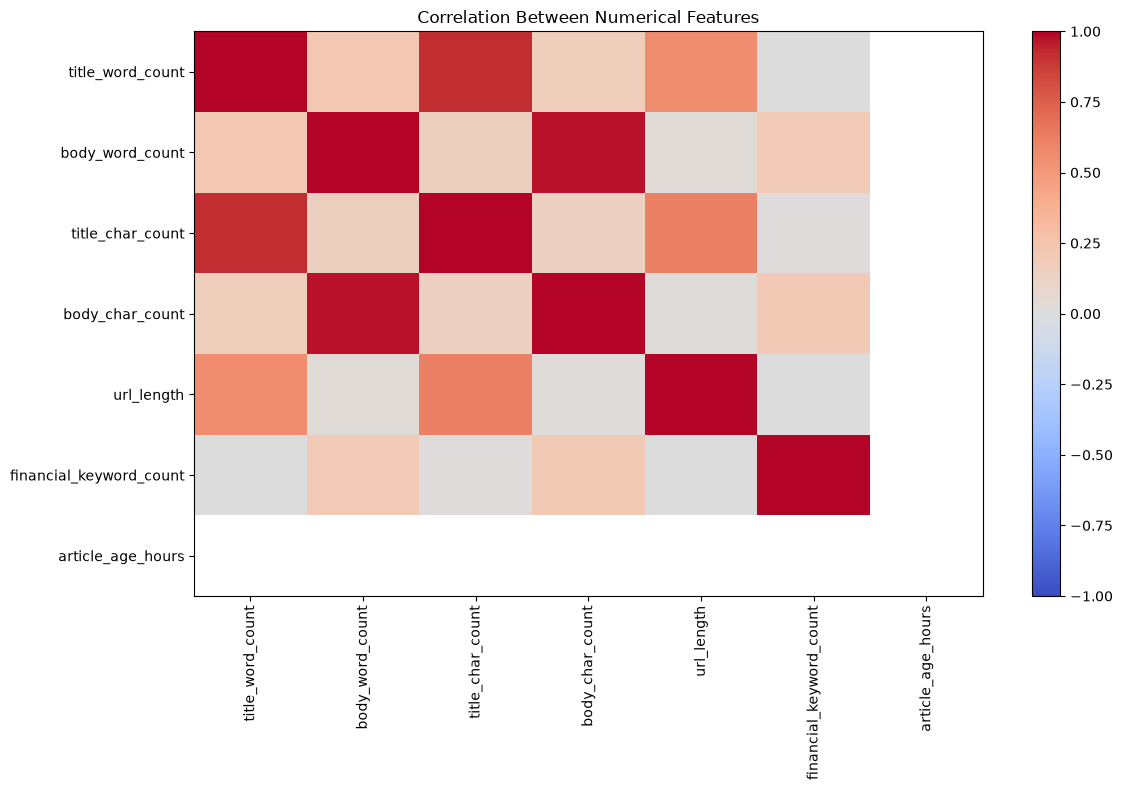

,title_word_count,body_word_count,title_char_count,body_char_count,url_length,financial_keyword_count,article_age_hours
title_word_count,1.00,0.21,0.92,0.17,0.56,-0.00,NaN
body_word_count,0.21,1.00,0.16,0.97,0.02,0.19,NaN
title_char_count,0.92,0.16,1.00,0.14,0.61,0.01,NaN
body_char_count,0.17,0.97,0.14,1.00,0.02,0.21,NaN
url_length,0.56,0.02,0.61,0.02,1.00,-0.00,NaN
financial_keyword_count,-0.00,0.19,0.01,0.21,-0.00,1.00,NaN
article_age_hours,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
numeric_columns = [
    "title_word_count",
    "body_word_count",
    "title_char_count",
    "body_char_count",
    "url_length",
    "financial_keyword_count",
    "article_age_hours"
]

numeric_columns = [
    col for col in numeric_columns
    if col in df.columns
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))
plt.imshow(
    correlation,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)
plt.colorbar()
plt.xticks(
    range(len(numeric_columns)),
    numeric_columns,
    rotation=90
)
plt.yticks(
    range(len(numeric_columns)),
    numeric_columns
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

display(correlation.round(2))

Highly correlated features may contain redundant information. However, do not automatically remove them: two correlated features can still have different predictive value.

### 16.2 Mutual information

Mutual information measures how much information a feature provides about a target. It can identify nonlinear relationships that ordinary correlation may miss.

In [114]:
from sklearn.feature_selection import mutual_info_classif

# Example: classification target
target = df["category"]

X_numeric = df[numeric_columns].copy()
X_numeric = X_numeric.replace(
    [np.inf, -np.inf],
    np.nan
)
# Median first; 0 as a fallback for columns that are entirely missing
X_numeric = X_numeric.fillna(
    X_numeric.median()
).fillna(0)

valid = target.notna()

mi_scores = mutual_info_classif(
    X_numeric.loc[valid],
    target.loc[valid].astype(str),
    random_state=42
)

mi_results = pd.DataFrame({
    "feature": X_numeric.columns,
    "mutual_information": mi_scores
})

mi_results = mi_results.sort_values(
    "mutual_information",
    ascending=False
)

display(mi_results)

,feature,mutual_information
1,body_word_count,0.115283
3,body_char_count,0.114302
5,financial_keyword_count,0.057191
0,title_word_count,0.030186
2,title_char_count,0.020041
4,url_length,0.008607
6,article_age_hours,0.000000


For rigorous evaluation, calculate feature-selection scores using training data only.

### 16.3 SelectKBest

`SelectKBest` selects the top K features according to a scoring function.

For TF-IDF, chi-squared feature selection is commonly used for classification. It requires non-negative feature values.

In [115]:
from sklearn.feature_selection import SelectKBest, chi2

selector = SelectKBest(
    score_func=chi2,
    k=100
)

Fit it only on training data. `X_train_tfidf` must be generated from training text only, so we create a quick split here for the demonstration.

In [116]:
from sklearn.model_selection import train_test_split

fs_df = df.dropna(subset=["category"])

fs_train_text, fs_test_text, fs_y_train, fs_y_test = train_test_split(
    fs_df["title_lower"],
    fs_df["category"].astype(str),
    test_size=0.20,
    random_state=42
)

fs_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)

# X_train_tfidf is generated from training text only.
X_train_tfidf = fs_tfidf.fit_transform(fs_train_text)
X_test_tfidf = fs_tfidf.transform(fs_test_text)

# k cannot be larger than the number of available features
selector.set_params(k=min(100, X_train_tfidf.shape[1]))

X_train_selected = selector.fit_transform(
    X_train_tfidf,
    fs_y_train
)

X_test_selected = selector.transform(
    X_test_tfidf
)

print("Before selection:", X_train_tfidf.shape)
print("After selection: ", X_train_selected.shape)

top_terms = fs_tfidf.get_feature_names_out()[selector.get_support()]
print("\nSample of selected terms:", top_terms[:20])

Before selection: (79920, 85444)
After selection:  (79920, 100)

Sample of selected terms: ['19' '2023 financial' 'ai' 'amazon' 'apple' 'available' 'aws energy'
 'aws healthimaging' 'aws healthomics' 'best stock' 'black hole'
 'campaign' 'cancer' 'changelog' 'chapea' 'clean energy' 'climate'
 'climate change' 'congress' 'coronavirus']


# Part I — Complete Leakage-Safe Machine Learning Pipeline

## 17. Prepare training and testing data

This is one of the most important sections.

A common mistake is to perform feature engineering on the complete dataset and then split it into training and testing data. This can cause **data leakage**.

A correct workflow is:

```
Raw news dataset
      ↓
Train / validation / test split
      ↓
Training data
      ↓
Fit vectorizers, encoders, scalers and model
      ↓
Test data
      ↓
Apply fitted transformations and evaluate
      ↓
Final evaluation
```

### 17.1 Define the target

For demonstration, we will predict the article category.

In [117]:
TARGET = "category"

model_df = df.dropna(
    subset=[TARGET]
).copy()

# Give missing categorical values a placeholder so the encoders receive plain strings
for col in ["domain_feature", "author"]:
    model_df[col] = model_df[col].fillna("unknown").astype(str)

X = model_df[[
    "title_lower",
    "text_lower",
    "domain_feature",
    "author",
    "title_word_count",
    "body_word_count",
    "url_length",
    "url_path_depth",
    "published_hour",
    "financial_keyword_count"
]]

y = model_df[TARGET].astype(str)

### 17.2 Split the dataset

Choose **one** of the two splitting approaches below. If you run both cells, the second (chronological) split replaces the first.

For a basic classification exercise:

In [118]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 79920
Testing records: 19980


For a real news prediction system, I recommend chronological splitting instead:

In [119]:
model_df = model_df.sort_values(
    "published_at"
).reset_index(drop=True)

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[X.columns]
X_test = test_df[X.columns]

y_train = train_df[TARGET].astype(str)
y_test = test_df[TARGET].astype(str)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 79920
Testing records: 19980


This simulates training on historical news and predicting future news.

If your task predicts future engagement, use the actual prediction timestamp to determine the split and ensure that labels are available only after their measurement window has completed.

## 18. Build a complete preprocessing pipeline

We will combine:

1. Numerical features → imputation and scaling.
2. Categorical features → imputation and one-hot encoding.
3. Title → TF-IDF.
4. Article body → TF-IDF.
5. Logistic Regression → classification.

In [120]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

Define feature groups:

In [121]:
numeric_features = [
    "title_word_count",
    "body_word_count",
    "url_length",
    "url_path_depth",
    "published_hour",
    "financial_keyword_count"
]

categorical_features = [
    "domain_feature",
    "author"
]

Numerical preprocessing:

In [122]:
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

Categorical preprocessing:

In [123]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

Combine the transformations:

In [124]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        ),
        (
            "title_tfidf",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2
            ),
            "title_lower"
        ),
        (
            "body_tfidf",
            TfidfVectorizer(
                max_features=15000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.98
            ),
            "text_lower"
        )
    ]
)

Build the model:

In [125]:
model = Pipeline([
    (
        "preprocessing",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

Train:

In [126]:
model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](6,)","['Energy','Health','Market/Stocks','Other','Politics','Technology']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['title_lower','text_lower','domain_feature',...,'url_path_depth', 'published_hour','financial_keyword_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in 

Predict:

In [127]:
y_pred = model.predict(
    X_test
)

Evaluate:

In [128]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)
print(
    "Precision:",
    precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)
print(
    "Recall:",
    recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)
print(
    "F1 Score:",
    f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

labels = sorted(set(y_test) | set(y_pred))
cm = confusion_matrix(y_test, y_pred, labels=labels)

print("Confusion Matrix (rows = actual, columns = predicted):")
display(pd.DataFrame(cm, index=labels, columns=labels))

Accuracy: 0.8063563563563564
Precision: 0.8114808970409196
Recall: 0.8063563563563564
F1 Score: 0.8035643745724769

Classification Report:

               precision    recall  f1-score   support

       Energy       0.54      0.57      0.55       185
       Health       0.74      0.43      0.54       780
Market/Stocks       0.39      0.23      0.29       442
        Other       0.73      0.88      0.80      6387
     Politics       0.55      0.63      0.59       534
   Technology       0.89      0.82      0.86     11652

     accuracy                           0.81     19980
    macro avg       0.64      0.59      0.60     19980
 weighted avg       0.81      0.81      0.80     19980

Confusion Matrix (rows = actual, columns = predicted):


,Energy,Health,Market/Stocks,Other,Politics,Technology
Energy,105,6,3,38,5,28
Health,6,335,7,240,13,179
Market/Stocks,3,2,100,117,10,210
Other,12,27,21,5644,45,638
Politics,3,5,11,77,336,102
Technology,67,75,112,1610,197,9591


This is a complete baseline. The feature transformations are learned from training data and reused on test data.

# Part J — Export Engineered Features

## 19. Create the final feature dataset

After engineering, create a structured dataset containing the features you want to inspect or use in subsequent experiments.

In [129]:
final_features = [
    # Title features
    "title_char_count",
    "title_word_count",
    "title_avg_word_length",
    "title_digit_count",
    "title_uppercase_ratio",
    "title_exclamation_count",
    "title_question_count",
    "title_unique_word_ratio",

    # Body features
    "body_char_count",
    "body_word_count",
    "body_sentence_count",
    "body_avg_sentence_length",
    "body_unique_word_ratio",

    # Financial features
    "financial_keyword_count",

    # URL features
    "url_length",
    "url_path_depth",
    "url_https",
    "url_slug_length",

    # Temporal features
    "published_year",
    "published_month",
    "published_hour",
    "published_dayofweek",
    "published_is_weekend",
    "article_age_hours",
    "published_hour_sin",
    "published_hour_cos",
    "published_day_sin",
    "published_day_cos",

    # Interaction features
    "title_body_length_ratio",
    "financial_keyword_density",
]

final_features = [
    col for col in final_features
    if col in df.columns
]

id_columns = [
    col for col in ["url", "domain_feature", "category"]
    if col in df.columns
]

feature_dataset = df[id_columns + final_features].copy()

feature_dataset.to_csv(
    "news_engineered_features.csv",
    index=False
)

print("Saved news_engineered_features.csv with shape:", feature_dataset.shape)
display(feature_dataset.head())

Saved news_engineered_features.csv with shape: (99900, 33)


,url,domain_feature,category,title_char_count,title_word_count,title_avg_word_length,title_digit_count,title_uppercase_ratio,title_exclamation_count,title_question_count,...,published_hour,published_dayofweek,published_is_weekend,article_age_hours,published_hour_sin,published_hour_cos,published_day_sin,published_day_cos,title_body_length_ratio,financial_keyword_density
0,https://www.androidauthority.com/this-free-app...,androidauthority.com,Technology,72,14,4.214286,0,0.041667,0,0,...,0.0,0.0,0,NaN,0.0,1.0,0.0,1.0,0.008883,0.000000
1,https://www.androidauthority.com/samsung-mocks...,androidauthority.com,Technology,68,13,4.307692,0,0.058824,0,0,...,0.0,0.0,0,NaN,0.0,1.0,0.0,1.0,0.032828,0.000000
2,https://www.androidauthority.com/matters-most-...,androidauthority.com,Technology,81,13,5.307692,0,0.037037,0,0,...,0.0,0.0,0,NaN,0.0,1.0,0.0,1.0,0.030806,0.000000
3,https://www.androidauthority.com/google-chrome...,androidauthority.com,Technology,61,10,5.100000,1,0.065574,0,0,...,0.0,0.0,0,NaN,0.0,1.0,0.0,1.0,0.006748,0.000675
4,https://www.androidauthority.com/google-wallet...,androidauthority.com,Technology,74,13,4.769231,1,0.054054,0,0,...,0.0,0.0,0,NaN,0.0,1.0,0.0,1.0,0.012311,0.000000


Note that this CSV contains the interpretable tabular features, not the fitted TF-IDF matrix or embeddings. Save those separately when needed.

## 20. Save the trained model

A fitted pipeline includes the preprocessing transformations and classifier.

In [130]:
import joblib

joblib.dump(
    model,
    "news_classification_pipeline.pkl"
)

['news_classification_pipeline.pkl']

Load it later:

In [131]:
loaded_model = joblib.load(
    "news_classification_pipeline.pkl"
)

predictions = loaded_model.predict(
    X_test
)

print(predictions[:10])

['Technology' 'Technology' 'Technology' 'Technology' 'Technology'
 'Technology' 'Technology' 'Technology' 'Technology' 'Technology']


This is important for production deployment because the same preprocessing logic must be applied to incoming articles.

# Part K — Student Practical Assignments

These exercises will help students move from understanding feature engineering to applying it in an industrial news-data project.

| Level | Assignment | Expected output |
|---|---|---|
| Beginner | Extract 15 title features | Numerical columns |
| Beginner | Extract 15 article-body features | Numerical columns |
| Beginner | Extract URL and domain features | URL feature table |
| Intermediate | Implement TF-IDF with unigrams and bigrams | Sparse matrix |
| Intermediate | Implement cyclical time encoding | Temporal features |
| Intermediate | Compare title-only and body-only TF-IDF | Model comparison |
| Advanced | Generate sentence embeddings | Embedding matrix |
| Advanced | Implement feature selection | Selected feature set |
| Advanced | Compare metadata-only, text-only, and combined features | Evaluation report |
| Advanced | Build leakage-safe preprocessing pipeline | Saved model pipeline |

## 21. Recommended industrial feature engineering pipeline

For LimeoX's news-data training, I recommend teaching the topics in this sequence:

**News feature engineering workflow**

1. **Raw dataset inspection** — Identify title, body, URL, domain, author, publication date and target.
2. **Text normalization** — Whitespace, missing text, HTML artifacts and normalized text copies.
3. **Numerical feature extraction** — Character counts, word counts, sentence lengths, ratios and keyword counts.
4. **URL and temporal features** — Domain, URL depth, publication hour, article age and cyclical encoding.
5. **Categorical encoding** — One-hot encoding and rare-category handling.
6. **NLP features** — Bag of Words, TF-IDF, n-grams and sentence embeddings.
7. **Feature selection** — Correlation, mutual information and SelectKBest.
8. **Model-ready dataset** — Leakage-safe pipeline, validation and feature export.

## 22. Important discussion: Which features should students actually use?

Not every engineered feature should automatically be included in a model. For example, if the project is predicting Google Discover clicks:

| Feature | Potential usefulness | Important consideration |
|---|---|---|
| Title TF-IDF | High | Headline wording |
| Title embeddings | High | Semantic meaning |
| Article body embeddings | Potentially high | Computational cost |
| Domain | Potentially high | Publisher bias |
| Publication hour | Potentially high | Time-dependent behaviour |
| Article age | High | Freshness |
| Body word count | Medium | Article structure |
| Financial keywords | Task-dependent | Domain-specific signal |
| Clicks/impressions | Target-dependent | Can create leakage |
| Article position | Target-dependent | May reveal ranking outcome |

**My recommendation:** Teach students to create a feature dictionary for every project. It should contain:

- Feature name
- Data type
- Source column
- Feature calculation
- Missing-value handling
- Prediction-time availability
- Potential leakage risk
- Whether the feature improved validation performance

This develops the habit of building explainable and reproducible ML systems, rather than simply generating hundreds of columns.

The most useful next practical exercise is to take your actual scraped-news CSV and have students produce three separate experiments: **metadata-only**, **TF-IDF-only**, and **combined-feature** models. Comparing these results will teach them which features genuinely add predictive value.